# 실험 2: 감성 패턴 클러스터별 별점 일관성 분석

**목적** -- 27차원 aspect-sentiment 벡터(별점은 입력에 넣지 않음)로 리뷰를 K-Modes 클러스터링하고, 클러스터마다 별점이 모이는지 흩어지는지 비교한다. 감성이 섞인(mixed) 비율이 높은 클러스터일수록 별점의 분산·엔트로피·MAE가 클 것이라는 가설을 검증한다.

**입력** (실험 1 결과 폴더 `results_*` 안의 파일)
- `train_review_vectors.parquet`, `test_review_vectors.parquet` : 리뷰별 27차원 aspect-sentiment 벡터(값 0/1) + `rating`
- `test_predictions.parquet` : test 리뷰의 실제/예측 별점과 `group`

**실행 순서**
- **셀 0** -- Google Drive에서 실험 1 번들 ZIP 선택, 설정 복원, 결과 폴더 지정
- **셀 1** -- `kmodes` 설치, import, 설정값
- **셀 2** -- 입력 로드·검증, 리뷰 유형(Step 1) 라벨링, 범주형 벡터(Step 2) 생성
- **셀 3** -- k 선택 + K-Modes 학습(train), train·test 클러스터 배정 -> `review_clusters.parquet` 저장
- **셀 4** -- Step 4-5 지표·검정 계산 -> **표 1, 표 2, 그림 1** 표시 및 저장

> 실험 2는 SBERT/ABSA 모델을 로드하지 않는다(CPU 런타임). 실험 1이 만든 벡터·예측 파일만 사용한다.

In [ ]:
from google.colab import drive
from pathlib import Path
import json, zipfile

drive.mount("/content/drive")
PROJECT = Path("/content/drive/MyDrive/shoe_project")

# 실험 1과 같은 규칙: 가장 최근 ZIP을 사용한다.
bundles = sorted(PROJECT.glob("shoe_absa_*.zip"))
if not bundles:
    raise FileNotFoundError(f"{PROJECT} 안에 shoe_absa_*.zip 파일이 없습니다.")
bundle = bundles[-1]

# ZIP 전체(약 1GB)를 풀지 않고 settings.json만 읽는다.
with zipfile.ZipFile(bundle) as archive:
    settings = json.loads(archive.read("settings.json").decode("utf-8"))

ASPECT_EN = settings["aspect_en"]
SENTIMENTS = settings["sentiments"]
OUT = PROJECT / f"results_{settings['bundle_id']}"   # 실험 1 결과 폴더

required = ["train_review_vectors.parquet", "test_review_vectors.parquet",
            "test_predictions.parquet"]
missing = [name for name in required if not (OUT / name).is_file()]
if missing:
    raise FileNotFoundError(f"실험 1 결과가 없습니다. 실험 1 노트북을 먼저 실행하세요: {missing}")

EXP2 = OUT / "experiment2"
EXP2.mkdir(exist_ok=True)
print("사용할 ZIP:", bundle.name)
print("실험 1 결과 폴더:", OUT)
print("실험 2 결과 폴더:", EXP2)

In [2]:
# kmodes 설치 (필요시)
%pip install -q kmodes

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import silhouette_score
from kmodes.kmodes import KModes
from IPython.display import display

matplotlib.rcParams["axes.unicode_minus"] = False

# ---- 설정 ----
ASPECTS = list(ASPECT_EN)          # 한글 aspect 9개 (순서 유지)
COLUMNS = [f"{a}_{s}" for a in ASPECTS for s in SENTIMENTS]
STATES = ["conflict", "pos", "neg", "neu", "none"]
STATE_TO_INT = {s: i for i, s in enumerate(STATES)}

MODELS = ["Linear regression", "Random forest"]
RANDOM_SEED = 42
K_RANGE = range(2, 13)
K = None                           # None이면 자동 선택, 숫자를 넣으면 그 값 사용
MIN_CLUSTER_SIZE = 100             # train 기준 최소 클러스터 크기
SILHOUETTE_SAMPLE = 10_000
SAME_VECTOR_MIN_N = 20

# 클러스터링 대상이 되는 리뷰 유형 (no_aspect는 제외)
CLUSTER_TYPE = ["mixed", "single_pos", "single_neg", "neutral_only"]
assert len(COLUMNS) == 27, f"aspect*3 = 27개여야 함 (실제 {len(COLUMNS)})"

Note: you may need to restart the kernel to use updated packages.


In [3]:
# ---- 입력 로드 및 검증 ----
def load_review_vectors(split):
    df = pd.read_parquet(OUT / f"{split}_review_vectors.parquet")
    if "review_id" in df.columns:                 # 실측 산출물은 review_id가 컬럼
        df = df.set_index("review_id")
    df["rating"] = df["rating"].astype(int)
    return df

train_vec = load_review_vectors("train")
test_vec  = load_review_vectors("test")
test_pred = pd.read_parquet(OUT / "test_predictions.parquet")
if "review_id" in test_pred.columns:
    test_pred = test_pred.set_index("review_id")

for split, vec in [("train", train_vec), ("test", test_vec)]:
    missing = [c for c in COLUMNS if c not in vec.columns]
    if missing:
        raise ValueError(f"{split} 벡터에 빠진 컬럼: {missing}")
    vals = set(np.unique(vec[COLUMNS].to_numpy()))
    if not vals.issubset({0, 1}):
        raise ValueError(f"{split} 벡터 값이 {{0,1}}이 아님: {vals}")
assert set(test_vec.index) == set(test_pred.index), "test 벡터와 test_predictions의 index가 다릅니다."
test_pred = test_pred.loc[test_vec.index]      # 행 순서 정렬

# ---- Step 1. 리뷰 유형 라벨링 (위에서부터 순서대로 판정) ----
def label_review_type(frame):
    pos = frame[[f"{a}_positive" for a in ASPECTS]].to_numpy(dtype=bool)
    neg = frame[[f"{a}_negative" for a in ASPECTS]].to_numpy(dtype=bool)
    neu = frame[[f"{a}_neutral" for a in ASPECTS]].to_numpy(dtype=bool)
    has_pos, has_neg, has_neu = pos.any(1), neg.any(1), neu.any(1)
    t = np.full(len(frame), "no_aspect", dtype=object)
    t[has_neu & ~has_pos & ~has_neg] = "neutral_only"
    t[has_neg & ~has_pos]            = "single_neg"
    t[has_pos & ~has_neg]            = "single_pos"
    t[has_pos & has_neg]             = "mixed"
    return pd.Series(t, index=frame.index)

train_vec["review_type"] = label_review_type(train_vec)
test_vec["review_type"]  = label_review_type(test_vec)

EXP1_GROUP = {"mixed": "mixed", "single_pos": "single", "single_neg": "single",
              "neutral_only": "neutral_or_unassigned", "no_aspect": "neutral_or_unassigned"}
assert (test_vec["review_type"].map(EXP1_GROUP).to_numpy() == test_pred["group"].to_numpy()).all(), \
    "Step 1 라벨이 실험 1의 group과 일치하지 않습니다."

# ---- Step 2. 9차원 범주형 벡터 (각 aspect: conflict/pos/neg/neu/none) ----
def build_C(frame):
    C = np.full((len(frame), len(ASPECTS)), "none", dtype=object)
    for j, a in enumerate(ASPECTS):
        p   = frame[f"{a}_positive"].to_numpy(dtype=bool)
        n   = frame[f"{a}_negative"].to_numpy(dtype=bool)
        neu = frame[f"{a}_neutral"].to_numpy(dtype=bool)
        st = np.full(len(frame), "none", dtype=object)
        st[p & n]         = "conflict"
        st[p & ~n]        = "pos"
        st[n & ~p]        = "neg"
        st[neu & ~p & ~n] = "neu"
        C[:, j] = st
    return C

def build_C_int(frame):
    return np.vectorize(STATE_TO_INT.get)(build_C(frame)).astype(np.int8)

C_train_int = build_C_int(train_vec)
C_test_int  = build_C_int(test_vec)
print("train 벡터:", train_vec.shape, "| test 벡터:", test_vec.shape)
print("리뷰 유형 분포(train+test):")
print(all_type_counts := pd.concat([train_vec["review_type"], test_vec["review_type"]],
                                   axis=0).value_counts())

train 벡터: (76320, 29) | test 벡터: (19080, 29)
리뷰 유형 분포(train+test):
no_aspect       46130
single_pos      27977
single_neg      13690
mixed            5820
neutral_only     1783
Name: review_type, dtype: int64


In [4]:
# ---- Step 3. K-Modes 클러스터링 (별점은 절대 입력하지 않음) ----
cache = EXP2 / "review_clusters.parquet"

if cache.exists():
    cluster_rows = pd.read_parquet(cache)
    print("기존 실행 결과를 불러왔습니다. 재학습을 원하면 파일을 삭제하세요:", cache)
else:
    train_mask = train_vec["review_type"].isin(CLUSTER_TYPE).to_numpy()
    C_TRAIN = C_train_int[train_mask]

    # k 선택: 최소 클러스터 크기 조건을 만족하는 k 중 silhouette(Hamming) 최대
    sil_rows = []
    for k in K_RANGE:
        km = KModes(n_clusters=k, init="Huang", n_init=10,
                    random_state=RANDOM_SEED, verbose=0)
        labels = km.fit_predict(C_TRAIN)
        sizes = np.bincount(labels, minlength=k)
        rng = np.random.RandomState(RANDOM_SEED)
        n_samp = min(SILHOUETTE_SAMPLE, len(C_TRAIN))
        idx = rng.choice(len(C_TRAIN), size=n_samp, replace=False)
        sil = silhouette_score(C_TRAIN[idx], labels[idx], metric="hamming")
        sil_rows.append((k, sil, int(sizes.min())))

    sil_df = pd.DataFrame(sil_rows, columns=["k", "silhouette", "min_cluster_size"])
    sil_df["ok"] = sil_df["min_cluster_size"] >= MIN_CLUSTER_SIZE
    candidates = sil_df[sil_df["ok"]]
    if candidates.empty:
        print("주의: 최소 클러스터 크기 조건을 만족하는 k가 없어 silhouette 최대 k를 사용합니다.")
        best_k = int(sil_df.loc[sil_df["silhouette"].idxmax(), "k"])
    else:
        best_k = int(candidates.loc[candidates["silhouette"].idxmax(), "k"])
    display(sil_df.head(20))
    print(f"선택한 k = {best_k} (silhouette {sil_df.loc[sil_df['k'] == best_k, 'silhouette'].iloc[0]:.2f})")

    km_model = KModes(n_clusters=best_k, init="Huang", n_init=10,
                      random_state=RANDOM_SEED, verbose=0)
    train_labels = km_model.fit_predict(C_TRAIN)

    train_cids = train_vec.index[train_mask].to_numpy()
    test_mask  = test_vec["review_type"].isin(CLUSTER_TYPE).to_numpy()
    test_cids  = test_vec.index[test_mask].to_numpy()
    test_labels = km_model.predict(C_test_int[test_mask])   # no_aspect(제외 대상)는 배정하지 않음

    cluster_rows = pd.DataFrame({
        "review_id":   np.concatenate([train_cids, test_cids]),
        "split":       np.concatenate([np.full(len(train_cids), "train"),
                                       np.full(len(test_cids), "test")]),
        "rating":      np.concatenate([train_vec.loc[train_cids, "rating"].to_numpy(),
                                       test_vec.loc[test_cids, "rating"].to_numpy()]),
        "review_type": np.concatenate([train_vec.loc[train_cids, "review_type"].to_numpy(),
                                       test_vec.loc[test_cids, "review_type"].to_numpy()]),
        "cluster":     np.concatenate([train_labels, test_labels]),
    })
    cluster_rows.to_parquet(cache, index=False)
    print("저장:", cache, "| 클러스터 수:", int(cluster_rows["cluster"].nunique()),
          "| 총 리뷰:", len(cluster_rows))

print("클러스터별 리뷰 수 (train+test):")
display(cluster_rows.groupby("cluster")["review_id"].size())

기존 실행 결과를 불러왔습니다. 재학습을 원하면 파일을 삭제하세요: /tmp/exp2_real/results_shoe_absa_20261123_094430/experiment2/review_clusters.parquet
클러스터별 리뷰 수 (train+test):


cluster
0    14890
1     3799
2     7098
3     2109
4     5277
5      854
6     4666
7      793
8     8078
9     1706
Name: review_id, dtype: int64

표 1. 클러스터 요약 (mixed_ratio 오름차순)


,cluster,pattern,n_reviews,mixed_ratio,rating_mean,rating_std,rating_entropy,n_test,mae_Linear regression,mae_Random forest
7,7,returns and exchanges:neu,793,0.029,1.880,1.183,1.806,158,1.295,0.979
5,5,delivery:pos,854,0.034,4.618,0.909,1.074,174,0.560,0.522
8,8,comfort:pos,8078,0.036,4.384,1.125,1.445,1569,0.590,0.561
6,6,functionality:pos,4666,0.048,3.875,1.409,1.958,1007,0.821,0.817
9,9,"comfort:pos, size and fit:pos",1706,0.075,4.706,0.643,0.995,319,0.351,0.458
0,0,size and fit:pos,14890,0.080,4.244,1.200,1.639,2964,0.796,0.787
2,2,size and fit:neg,7098,0.088,3.062,1.388,2.308,1313,1.161,1.130
4,4,durability:neg,5277,0.117,2.275,1.439,2.072,1042,0.997,0.934
1,1,design:pos,3799,0.152,4.411,1.049,1.451,765,0.670,0.631
3,3,size and fit:conflict,2109,1.000,3.409,1.307,2.244,405,1.093,1.076


클러스터 단위 Spearman (mixed_ratio vs): rating_std rho=0.345 (p=0.328), rating_entropy rho=0.479 (p=0.162), mae_Random forest rho=0.358 (p=0.310)
표 2. 리뷰 유형별 비교


,review_type,n_reviews,rating_mean,rating_std,rating_entropy,mae_Linear regression,mae_Random forest,same_vector_std,levene_p_vs_mixed
0,mixed,5820,3.384,1.381,2.261,1.075,1.049,1.256,NaN
1,single_pos,27977,4.560,0.899,1.234,0.618,0.611,0.839,0.000
2,single_neg,13690,2.528,1.388,2.228,1.116,1.062,1.263,0.038
3,neutral_only,1783,3.342,1.597,2.174,1.177,1.103,1.338,NaN
4,no_aspect,46130,4.150,1.343,1.649,1.092,1.078,1.343,NaN


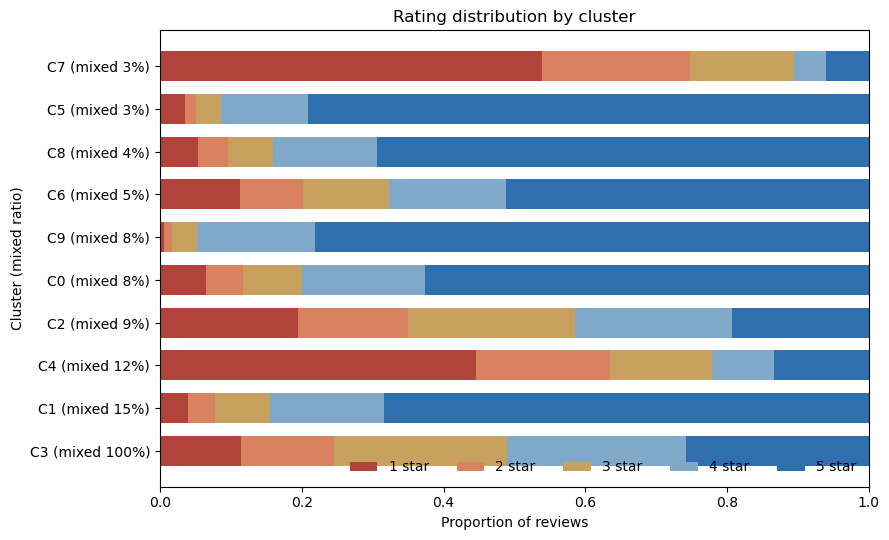

저장: /tmp/exp2_real/results_shoe_absa_20261123_094430/experiment2/experiment2_rating_by_cluster.png


In [5]:
# ---- Step 4-5. 지표·검정 계산 및 표·그림 ----
cl = pd.read_parquet(EXP2 / "review_clusters.parquet")

# 클러스터별 범주형 벡터 재구성(패턴 추출용). cells 0~2의 함수·변수 재사용
tr = load_review_vectors("train"); tr["review_type"] = label_review_type(tr)
te = load_review_vectors("test");  te["review_type"] = label_review_type(te)
all_v = pd.concat([tr, te], axis=0)                    # index: review_id
cl_map = cl.set_index("review_id")["cluster"]

def modal_patterns(frame, cluster_by_id):
    C = build_C(frame)
    Cdf = pd.DataFrame(C, columns=ASPECTS, index=frame.index)
    Cdf["__cluster"] = cluster_by_id.reindex(frame.index).to_numpy()
    out = {}
    for cid, sub in Cdf.groupby("__cluster"):
        parts = []
        for a in ASPECTS:
            st = sub[a].mode().iloc[0]
            if st != "none":
                parts.append(f"{ASPECT_EN[a]}:{st}")
        out[cid] = ", ".join(parts) if parts else "none"
    return out

patterns = modal_patterns(all_v, cl_map)

def rating_entropy(s):
    vc = s.value_counts(normalize=True)
    p = vc.to_numpy()
    return float(-(p * np.log2(p)).sum())

# --- 표 1. 클러스터 요약 (메인 결과) ---
g = cl.groupby("cluster")
cluster_metrics = g.agg(
    n_reviews=("review_id", "size"),
    mixed_ratio=("review_type", lambda s: (s == "mixed").mean()),
    rating_mean=("rating", "mean"),
    rating_std=("rating", "std"),                   # ddof=1
)
cluster_metrics["rating_entropy"] = g["rating"].apply(rating_entropy)

# test만으로 MAE 조인 (test_predictions)
tcl = cl[cl["split"] == "test"].set_index("review_id")
tall = tcl.join(test_pred[["actual_rating", *MODELS]])
tall["err_lr"] = (tall["actual_rating"] - tall["Linear regression"]).abs()
tall["err_rf"] = (tall["actual_rating"] - tall["Random forest"]).abs()
mae_g = tall.groupby("cluster").agg(
    n_test=("err_lr", "size"),
    mae_LR=("err_lr", "mean"),
    mae_RF=("err_rf", "mean"),
).rename(columns={"mae_LR": "mae_Linear regression", "mae_RF": "mae_Random forest"})
cluster_metrics = cluster_metrics.join(mae_g)

cluster_metrics["pattern"] = cluster_metrics.index.map(patterns)
summary = cluster_metrics.reset_index().sort_values("mixed_ratio")
summary = summary[["cluster", "pattern", "n_reviews", "mixed_ratio",
                   "rating_mean", "rating_std", "rating_entropy",
                   "n_test", "mae_Linear regression", "mae_Random forest"]]
summary["mixed_ratio"] = summary["mixed_ratio"].round(3)
summary["rating_mean"] = summary["rating_mean"].round(3)
summary["rating_std"] = summary["rating_std"].round(3)
summary["rating_entropy"] = summary["rating_entropy"].round(3)
summary["mae_Linear regression"] = summary["mae_Linear regression"].round(3)
summary["mae_Random forest"] = summary["mae_Random forest"].round(3)

print("표 1. 클러스터 요약 (mixed_ratio 오름차순)")
display(summary)

sp = {c: stats.spearmanr(summary["mixed_ratio"], summary[c])
      for c in ["rating_std", "rating_entropy", "mae_Random forest"]}
print("클러스터 단위 Spearman (mixed_ratio vs): " +
      ", ".join(f"{c} rho={r:.3f} (p={p:.3f})" for c, (r, p) in sp.items()))

# --- 표 2. 리뷰 유형별 비교 ---
tg = all_v.groupby("review_type")
type_summary = tg.agg(
    n_reviews=("review_type", "size"),
    rating_mean=("rating", "mean"),
    rating_std=("rating", "std"),
)
type_summary["rating_entropy"] = tg["rating"].apply(rating_entropy)

tpred = test_pred[["actual_rating", *MODELS]]
tby = test_vec.join(tpred, how="left")               # index: review_id
tby["err_lr"] = (tby["actual_rating"] - tby["Linear regression"]).abs()
tby["err_rf"] = (tby["actual_rating"] - tby["Random forest"]).abs()
mae_type = tby.groupby("review_type")[["err_lr", "err_rf"]].mean().rename(
    columns={"err_lr": "mae_Linear regression", "err_rf": "mae_Random forest"})
type_summary = type_summary.join(mae_type)

# 동일 벡터 그룹의 별점 std (sanity check)
grp = all_v.groupby(COLUMNS)["rating"].agg(["size", "std"]).reset_index()
grp = grp[grp["size"] >= SAME_VECTOR_MIN_N][COLUMNS + ["std"]]
m = all_v.reset_index().merge(grp, on=COLUMNS, how="left").set_index("review_id")
type_summary["same_vector_std"] = m.groupby("review_type")["std"].mean()

# Levene 검정 (mixed vs single_pos / mixed vs single_neg)
def ratings_of(t):
    return all_v.loc[all_v["review_type"] == t, "rating"].to_numpy()

lv = {}
for other in ["single_pos", "single_neg"]:
    r_mix, r_oth = ratings_of("mixed"), ratings_of(other)
    if len(r_mix) >= 2 and len(r_oth) >= 2:
        _, p = stats.levene(r_mix, r_oth, center="median")
        lv[other] = p
    else:
        lv[other] = np.nan
type_summary["levene_p_vs_mixed"] = pd.Series(lv).reindex(type_summary.index)

ORDER_TYPES = ["mixed", "single_pos", "single_neg", "neutral_only", "no_aspect"]
type_summary = type_summary.reindex(ORDER_TYPES).reset_index()
type_summary = type_summary[["review_type", "n_reviews", "rating_mean", "rating_std",
                             "rating_entropy", "mae_Linear regression",
                             "mae_Random forest", "same_vector_std", "levene_p_vs_mixed"]]
for c in ["rating_mean", "rating_std", "rating_entropy", "mae_Linear regression",
          "mae_Random forest", "same_vector_std", "levene_p_vs_mixed"]:
    type_summary[c] = type_summary[c].round(3)

print("표 2. 리뷰 유형별 비교")
display(type_summary)

# --- 저장 (표 1, 표 2) ---
summary.to_csv(EXP2 / "experiment2_cluster_summary.csv", index=False)
type_summary.to_csv(EXP2 / "experiment2_type_summary.csv", index=False)

# --- 그림 1. 클러스터별 별점 분포 (100% 누적 가로 막대) ---
piv = pd.crosstab(cl["cluster"], cl["rating"], normalize="index").reindex(summary["cluster"])
mixed_map = dict(zip(summary["cluster"], summary["mixed_ratio"]))
labels = [f"C{c} (mixed {mixed_map[c]:.0%})" for c in piv.index]

RATING_COLORS = {5: "#2f6fb0", 4: "#7fa8c9", 3: "#c9a15e", 2: "#d9825f", 1: "#b0433a"}

fig, ax = plt.subplots(figsize=(9, max(4, 0.55 * len(piv))))
bottom = np.zeros(len(piv))
for r in range(1, 6):
    vals = piv[r].to_numpy() if r in piv.columns else np.zeros(len(piv))
    ax.barh(labels, vals, left=bottom, height=0.7, color=RATING_COLORS[r], label=f"{r} star")
    bottom += vals
ax.set_xlabel("Proportion of reviews")
ax.set_ylabel("Cluster (mixed ratio)")
ax.set_title("Rating distribution by cluster")
ax.set_xlim(0, 1)
ax.legend(loc="lower right", ncol=5, frameon=False)
ax.invert_yaxis()
plt.tight_layout()
fig.savefig(EXP2 / "experiment2_rating_by_cluster.png", dpi=150, bbox_inches="tight")
plt.show()
print("저장:", EXP2 / "experiment2_rating_by_cluster.png")

## 부록 — aspect별 별점 패널티: "부정이 정보다"의 근거

어느 aspect의 부정이 별점을 **얼마나 깎는지**(Ridge 계수)와, 그 신호가 나온 리뷰들의 평균 별점. 실험 2의 "클러스터 7(반품/교환, 평균 1.88점)"이 왜 그렇게 나왔는지, 그리고 실험 1의 "MAE 개선 8.6%가 왜 작은가"를 하나로 이어주는 표다.

In [ ]:
# ---- 부록: aspect별 별점 패널티 계산 (test 기준, Ridge) ----
from sklearn.linear_model import Ridge

X = test_vec[COLUMNS].to_numpy()
y = test_vec["rating"].to_numpy()
ridge = Ridge(alpha=1.0).fit(X, y)

rows = []
for j, col in enumerate(COLUMNS):
    mentioned = test_vec[col] == 1
    n = int(mentioned.sum())
    rows.append([col, n, test_vec.loc[mentioned, "rating"].mean() if n else np.nan, ridge.coef_[j]])
pen = pd.DataFrame(rows, columns=["신호", "n", "평균 별점", "Ridge 계수"]).round(3)

neg_tbl = pen[pen["신호"].str.endswith("negative")].sort_values("Ridge 계수")
pos_tbl = pen[pen["신호"].str.endswith("positive")].sort_values("Ridge 계수", ascending=False)
ret = test_vec[[f"반품/교환_{s}" for s in SENTIMENTS]].any(axis=1)
ret_row = pd.DataFrame([["반품/교환 (아무 감성)", int(ret.sum()), round(test_vec.loc[ret, "rating"].mean(), 3), ""]],
                       columns=["신호", "n", "평균 별점", "Ridge 계수"])

display(neg_tbl)
display(pos_tbl)
display(ret_row)

,신호,n,평균 별점,Ridge 계수
13,내구성_negative,1027,2.016,-1.859
22,가격/가성비_negative,149,1.544,-1.650
10,반품/교환_negative,95,1.968,-1.393
7,착화감_negative,500,2.680,-1.136
19,기능_negative,561,2.832,-0.902
25,사이즈/핏_negative,1789,3.136,-0.891
1,디자인_negative,96,3.177,-0.772
4,배송_negative,20,3.550,-0.415
16,사진-실물 일치_negative,0,NaN,0.000


,신호,n,평균 별점,Ridge 계수
6,착화감_positive,1987,4.622,0.573
3,배송_positive,232,4.608,0.514
18,기능_positive,887,4.504,0.439
0,디자인_positive,866,4.508,0.410
15,사진-실물 일치_positive,113,4.646,0.399
24,사이즈/핏_positive,3444,4.256,0.287
12,내구성_positive,311,3.891,0.070
21,가격/가성비_positive,184,4.027,0.067
9,반품/교환_positive,16,2.062,-1.383


,신호,n,평균 별점,Ridge 계수
0,반품/교환 (아무 감성),359,2.019,


**이 표와 E 실험의 관계, 그리고 "더 개선" 시도 결과.**

- **패널티 표 = "어떤 부정이"**, **E-2 실험 = "그 부정이 얼마나 강한지"**. 같은 부정이라도 완곡하면 패널티가 무력화되는데(사이즈/핏), E-2는 그 '강도 축'을 특성으로 넣어 예측을 개선했다.
- **더 개선 시도 결과 (같은 데이터로 검증):** aspect별 패널티를 개별 특성으로 넣으면 0.9271로 집계 특성(0.9266)보다 못하고, 긍정 차원을 제거하면 0.9747로 오히려 악화된다(표의 "긍정 계수≈0"은 선형 해석이고, RF에선 긍정 차원이 single_pos를 구분하는 데 쓰임).
- → **이 표현(27차원 + 부정 강도)으로는 예측이 포화.** 더 큰 개선은 (1) 미배정 리뷰 49% 복구, (2) regex 대신 LLM 심각도 판정, 두 **추출 단계** 레버에 있다.